In [75]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np


In [22]:
DATA_PATH = Path("../data/raw/SMSSpamCollection")

df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    header=None,
    names=["label", "message"],
)

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [24]:
print("First rows:")
print(df.head())

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isna().sum())

First rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Shape:
(5572, 2)

Columns:
Index(['label', 'message'], dtype='object')

Missing values:
label      0
message    0
dtype: int64


In [26]:
X = df["message"]
y = df["label"]

print("\nX:")
print(X.head())

print("\ny:")
print(y.head())


X:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: object

y:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: object


In [28]:
class_counts = df["label"].value_counts()

print("\nClass counts:")
print(class_counts)


Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64


In [30]:
class_percentages = (
    df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nClass percentages:")
print(class_percentages)


Class percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


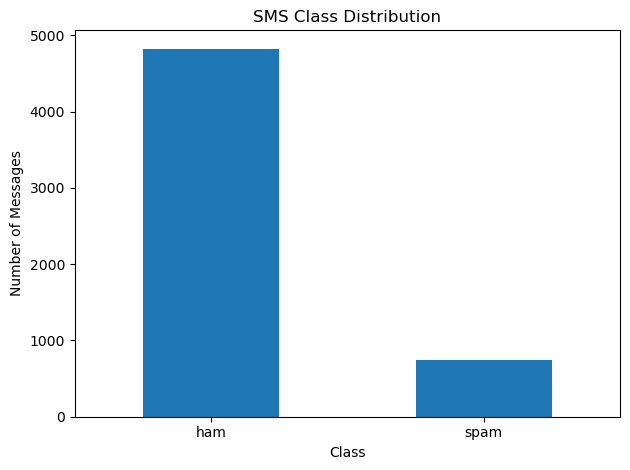

In [42]:
import matplotlib.pyplot as plt

class_counts.plot(kind="bar")

plt.title("SMS Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [55]:
# split off 20%:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [57]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp,
)

In [59]:
print(f"Train size: {len(X_train)}")
print(f"Validation size: {len(X_val)}")
print(f"Test size: {len(X_test)}")

Train size: 4457
Validation size: 557
Test size: 558


In [63]:
print("\nTrain distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))


Train distribution:
label
ham     0.865829
spam    0.134171
Name: proportion, dtype: float64

Validation distribution:
label
ham     0.867145
spam    0.132855
Name: proportion, dtype: float64

Test distribution:
label
ham     0.865591
spam    0.134409
Name: proportion, dtype: float64


In [90]:

from sklearn.metrics import accuracy_score, f1_score

majority_class = y_train.mode()[0]

baseline_predictions = np.full(
    shape=len(y_val),
    fill_value=majority_class,
)

In [69]:
y_train.mode()[0]

'ham'

In [73]:

baseline_accuracy = accuracy_score(
    y_val,
    baseline_predictions, 
)

baseline_f1 = f1_score(
    y_val,
    baseline_predictions,
    pos_label="spam",
)

print("\nMajority baseline:")
print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"F1:       {baseline_f1:.4f}")


Majority baseline:
Accuracy: 0.8671
F1:       0.0000


In [96]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
print(X_train_tfidf)

  (0, 1861)	0.6105144115989549
  (0, 3290)	0.544310621752537
  (0, 7629)	0.20665147747321655
  (0, 7439)	0.3449147101637941
  (0, 3373)	0.4114937543245475
  (1, 403)	0.22733432465493444
  (1, 6881)	0.24699163233312618
  (1, 3637)	0.17898852061390808
  (1, 3759)	0.24699163233312618
  (1, 6748)	0.24699163233312618
  (1, 4770)	0.10916978097154768
  (1, 4645)	0.24699163233312618
  (1, 2419)	0.24699163233312618
  (1, 2421)	0.24699163233312618
  (1, 390)	0.24699163233312618
  (1, 5558)	0.24699163233312618
  (1, 3873)	0.10684912254413216
  (1, 4981)	0.24699163233312618
  (1, 7133)	0.24699163233312618
  (1, 3608)	0.10725717994828715
  (1, 2420)	0.24699163233312618
  (1, 6927)	0.17425095024902573
  (1, 3629)	0.24699163233312618
  (1, 4812)	0.09745199974611543
  (1, 7107)	0.11133917024242793
  :	:
  (4455, 6859)	0.2086515841172273
  (4455, 3648)	0.09239122269767262
  (4456, 3559)	0.32964432662628707
  (4456, 3231)	0.32964432662628707
  (4456, 994)	0.2311334166971226
  (4456, 2828)	0.268727654878

In [84]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(
    max_iter=1000,
)
model.fit(
    X_train_tfidf,
    y_train,
)

LogisticRegression(max_iter=1000)

In [86]:
val_predictions = model.predict(X_val_tfidf)

In [88]:
model_accuracy = accuracy_score(
    y_val,
    val_predictions,
)

model_f1 = f1_score(
    y_val,
    val_predictions,
    pos_label="spam",
)

print("\nTF-IDF + Logistic Regression:")
print(f"Accuracy: {model_accuracy:.4f}")
print(f"F1:       {model_f1:.4f}")


TF-IDF + Logistic Regression:
Accuracy: 0.9731
F1:       0.8872
